### Jargons Summary

| Name | Full Name | Description |
|---|---|---|
| ReLU | Rectified Linear Unit | Activation function |
| SiLU | Sigmoid Linear Unit | Activation function |
| Swish | Swish | Another name for SiLU (commonly used form) |
| GLU | Gated Linear Unit | A gating mechanism based on element-wise multiplication |
| SwiGLU | Swish Gated Linear Unit | GLU variant using Swish/SiLU activation |

### ReLU vs. SiLU
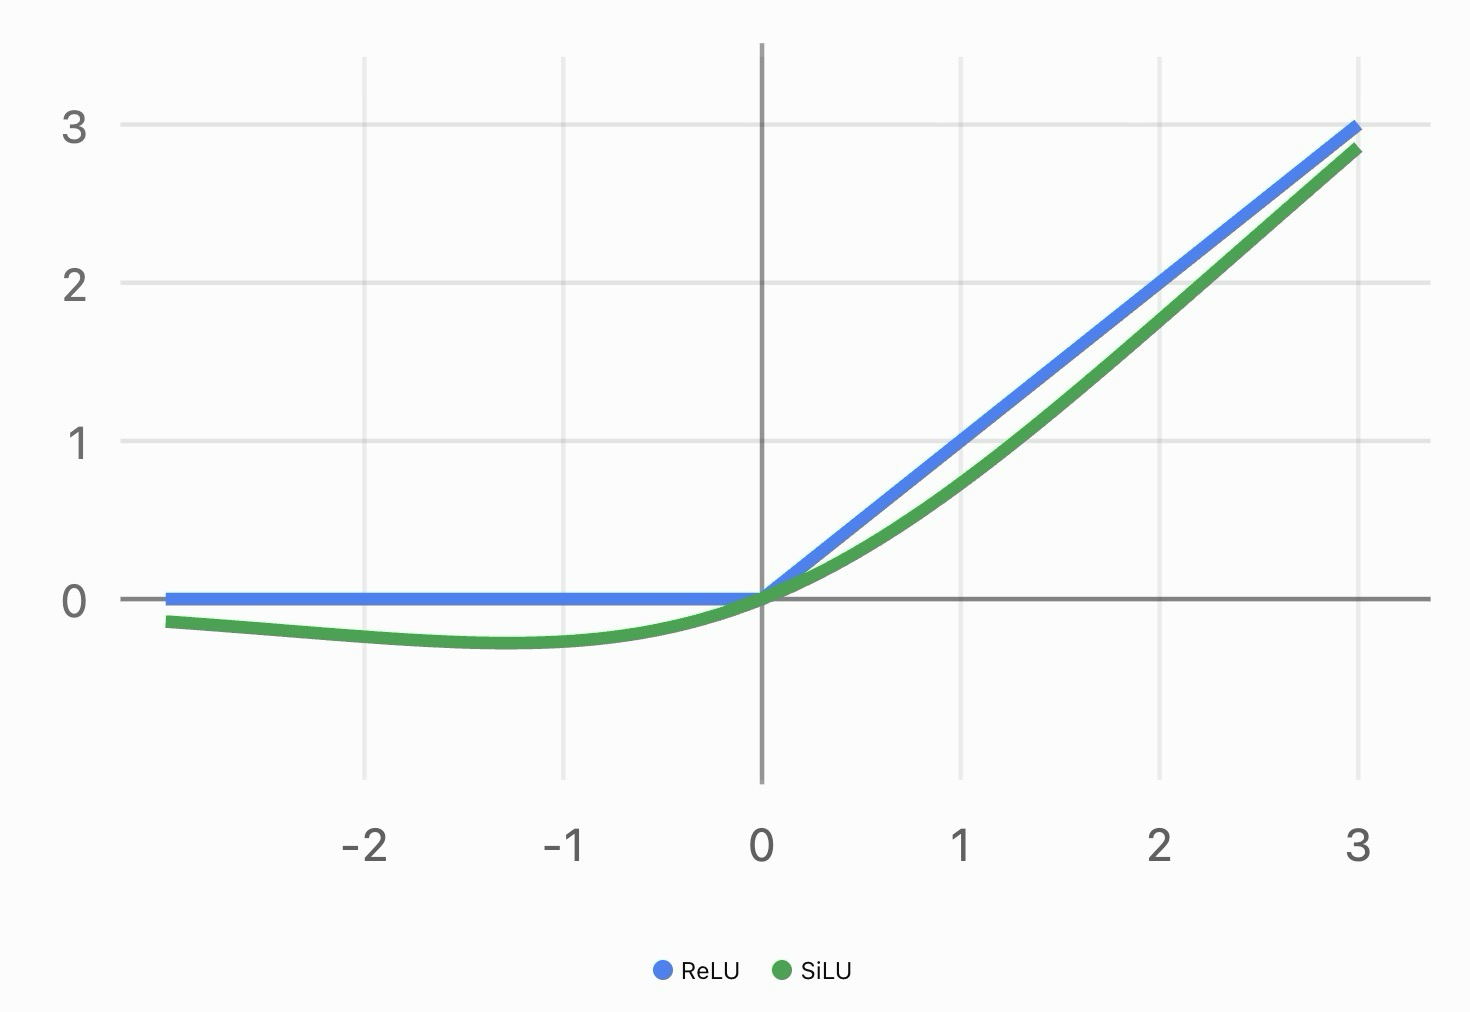

>Note:
>
>Sigmoid(x) = 1 / (1 + e^(-x))
>
>x really large -> close to 1
>
>x = 0 -> 0.5
>
>x really small -> close to 0
>
>SiLU(x) = x * Sigmoid(x)

In [1]:
import torch
import torch.nn.functional as F

x = torch.tensor([-3., -1., 0., 1., 3.])

print("ReLU:", [round(v, 3) for v in F.relu(x).tolist()])
print("SiLU:", [round(v, 3) for v in F.silu(x).tolist()])

# Verify the SiLU formula
print(torch.allclose(F.silu(x), x * torch.sigmoid(x)))

ReLU: [0.0, 0.0, 0.0, 1.0, 3.0]
SiLU: [-0.142, -0.269, 0.0, 0.731, 2.858]
True


In [2]:
import torch
import torch.nn.functional as F

# SwiGLU = SiLU(a) * b
# A Toy example:

a = torch.tensor([2., -2.])
b = torch.tensor([0.5, -3.])

h = F.silu(a) * b

print("a:", a)
print("b:", b)
print("SiLU(a):", F.silu(a))
print("hidden:", h)

a: tensor([ 2., -2.])
b: tensor([ 0.5000, -3.0000])
SiLU(a): tensor([ 1.7616, -0.2384])
hidden: tensor([0.8808, 0.7152])


### Deeper dive

Compare to ReluFFN, which contains
> 1 up projection: dim * hidden
>
> 1 down projection: dim * hidden
>
> total weights = 2 * dim * hidden

SwiGLUFFN has 1 additional set of weights, which is
> projection to gates: dim * hidden
>
> so 3 * dim * hidden
>
> 1.5x of ReluFFN weights.


#### Tensor Shape

Ex. in code

>x = torch.randn(2, 3, 4)

B * T * D

>first is Batch size (B)
>
>second is sequence length (T), a.k.a how many tokens in this sentence
>
>thrid is hidden dimension (D), or called model dimension（d_model), at first it's also embedding dimension.


#### Ideas behind SwiGLU

Architecture design is not just about what a network **can learn**, but also about what it **can learn efficiently**.

ReLU already provides non-linearity, but SwiGLU explicitly builds multiplicative interactions into its architecture.

This is an example of an **inductive bias**. We purposefully introduced a bias, even though UAT tells us a sufficiently large MLP is already powerful.

Attention is also a inductive bias. It explicitly provides a mechanism for tokens to exchange information, rather than expecting a generic network to learn such interactions on its own.


In [4]:
import torch
from torch import nn
import torch.nn.functional as F

class SwiGLUFFN(nn.Module):
    def __init__(self, dim=4, hidden=6):
        super().__init__()

        # read forward() to understand their roles!!       
        self.fc1 = nn.Linear(dim, hidden, bias=False)
        self.fc2 = nn.Linear(dim, hidden, bias=False)
        self.fc3 = nn.Linear(hidden, dim, bias=False)

    def forward(self, x):
        a = F.silu(self.fc1(x))
        b = self.fc2(x)
        return self.fc3(a * b)


torch.manual_seed(0)

model = SwiGLUFFN()
x = torch.randn(2, 3, 4)

y = model(x)

print("Input:", x.shape)
print("Output:", y.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

loss = y.square().mean()
loss.backward()

for name, p in model.named_parameters():
    print(name, round(p.grad.abs().sum().item(), 6))

Input: torch.Size([2, 3, 4])
Output: torch.Size([2, 3, 4])
Parameters: 72
fc1.weight 0.030158
fc2.weight 0.060782
fc3.weight 0.05164
